# Tiamat — Explicabilidade e análise de erros

Investigar como o pipeline selecionado se comporta na validação, sem alterar o modelo ou acessar o teste. A importância por permutação é o experimento principal desta etapa.

Esses resultados descrevem o pipeline e a amostra; não demonstram causalidade. Se decidir criar novos experimentos a partir daqui, use outra execução e não reutilize o teste já consultado para validar as novas decisões.


In [1]:
from pathlib import Path
import hashlib
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import optuna
from IPython.display import display, Markdown
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)

SEED = 210906
LANCE = 40
MIN_CONFIGURACOES = 100
MODELOS = ['Regressao_Logistica', 'Random_Forest', 'Gradient_Boosting', 'XGBoost', 'SVM']
ATRIBUTOS = [
    'rank_b', 'rank_w', 'komi', 'handicap',
    'maior_grupo_b', 'maior_grupo_w',
    'liberdades_maior_grupo_b', 'liberdades_maior_grupo_w',
    'pedras_em_jogo_b', 'pedras_em_jogo_w',
    'pedras_capturadas_por_b', 'pedras_capturadas_por_w',
    'distancia_media_tengen_b', 'distancia_media_tengen_w',
    'quantidade_grupos_b', 'quantidade_grupos_w',
    'tamanho_medio_grupos_b', 'tamanho_medio_grupos_w',
    'liberdades_medias_grupos_b', 'liberdades_medias_grupos_w',
    'grupos_em_atari_b', 'grupos_em_atari_w',
    'pedras_em_atari_b', 'pedras_em_atari_w'
]
CANDIDATOS = [Path('data/piloto_final/lance_040.csv'),
    Path('data/piloto_corrigido/lance_040.csv'), Path('data/piloto/lance_040.csv'),
    Path('data/processed/lance_040.csv'), Path('lance_040.csv')]
ARQUIVO_CSV = next((p for p in CANDIDATOS if p.exists()), None)
if ARQUIVO_CSV is None:
    raise FileNotFoundError('Ajuste CANDIDATOS para localizar o mesmo CSV usado no notebook 03.')
PASTA = Path('results/lance_040')
PASTA.mkdir(parents=True, exist_ok=True)
FIGURAS = PASTA / 'figuras'
FIGURAS.mkdir(exist_ok=True)

def sha256_arquivo(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def ler_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def salvar_json(path, value):
    Path(path).write_text(json.dumps(value, ensure_ascii=False, indent=2,
        allow_nan=False), encoding='utf-8')

def carregar_dados(split):
    dados = pd.read_csv(ARQUIVO_CSV)
    dados = dados.loc[dados['split'].eq(split)].copy()
    if not len(dados):
        raise ValueError(f'Conjunto {split} vazio.')
    assert dados.game_id.is_unique
    assert dados.lance.eq(LANCE).all()
    assert dados.vencedor.isin(['B', 'W']).all()
    return dados

def separar_xy(dados):
    X = dados[ATRIBUTOS].apply(pd.to_numeric, errors='raise')
    y = dados.vencedor.map({'B': 0, 'W': 1}).astype(int)
    assert not np.isinf(X.to_numpy()).any()
    return X, y

def pontuacoes(modelo, X):
    if hasattr(modelo, 'predict_proba'):
        classe_w = list(modelo.classes_).index(1)
        return modelo.predict_proba(X)[:, classe_w], 'probabilidade_W'
    return np.asarray(modelo.decision_function(X)).ravel(), 'margem_W'

def metricas_predicoes(y, pred, score):
    y = np.asarray(y)
    return {'n': int(len(y)), 'accuracy': float(accuracy_score(y, pred)),
        'balanced_accuracy': float(balanced_accuracy_score(y, pred)),
        'f1_macro': float(f1_score(y, pred, average='macro', zero_division=0)),
        'roc_auc': float(roc_auc_score(y, score)) if len(np.unique(y)) == 2 else np.nan}

def avaliar_modelo(modelo, dados):
    X, y = separar_xy(dados)
    pred = modelo.predict(X)
    score, tipo = pontuacoes(modelo, X)
    tabela = pd.DataFrame({'game_id': dados.game_id.to_numpy(),
        'y_real': y.to_numpy(), 'y_pred': pred, 'score_W': score,
        'tipo_score': tipo, 'acertou': pred == y.to_numpy()})
    return metricas_predicoes(y, pred, score), tabela

def carregar_estudos():
    estudos, linhas = {}, []
    for nome in MODELOS:
        db = (PASTA / f'optuna_{nome}.db').resolve()
        distintos = completos = 0
        melhor = np.nan
        if db.exists():
            # Mesmo nome de estudo e formato SQLite do notebook 03 antigo.
            estudo = optuna.load_study(study_name=f'tiamat_lance40_{nome}',
                storage=f'sqlite:///{db.as_posix()}')
            estudos[nome] = estudo
            trials = [t for t in estudo.trials
                if t.state == optuna.trial.TrialState.COMPLETE and t.value is not None]
            completos = len(trials)
            distintos = len({json.dumps(t.params, sort_keys=True) for t in trials})
            if completos:
                melhor = float(estudo.best_value)
        resumo_path = PASTA / f'resumo_{nome}.json'
        if resumo_path.exists():
            resumo = ler_json(resumo_path)
            if (resumo.get('seed') != SEED or resumo.get('lance') != LANCE
                    or resumo.get('folds') != 5):
                raise ValueError(f'Resumo de {nome} incompatível com o protocolo do 03 antigo.')
        linhas.append({'modelo': nome, 'configuracoes_distintas': distintos,
            'trials_completos': completos, 'roc_auc_cv': melhor,
            'pronto': distintos >= MIN_CONFIGURACOES})
    return estudos, pd.DataFrame(linhas)

def carregar_selecionado():
    selecao = ler_json(PASTA / 'selecao_congelada.json')
    if selecao.get('origem') != '03_antigo':
        raise ValueError('A seleção existente não foi produzida por esta sequência compatível.')
    if selecao['sha256_csv'] != sha256_arquivo(ARQUIVO_CSV):
        raise ValueError('O CSV foi alterado após a seleção. Preserve os dados desta execução.')
    path = PASTA / selecao['arquivo_modelo']
    if selecao['sha256_modelo'] != sha256_arquivo(path):
        raise ValueError('O modelo selecionado foi alterado após o congelamento.')
    return joblib.load(path), selecao

print('CSV:', ARQUIVO_CSV, '| resultados:', PASTA)
print('SEED:', SEED, '| 24 atributos | compatível com o notebook 03 original')


CSV: data\piloto_final\lance_040.csv | resultados: results\lance_040
SEED: 210906 | 24 atributos | compatível com o notebook 03 original


## 1. Pipeline congelado e matriz de confusão


,val
n,270.000000
accuracy,0.577778
balanced_accuracy,0.577795
f1_macro,0.577755
roc_auc,0.608254


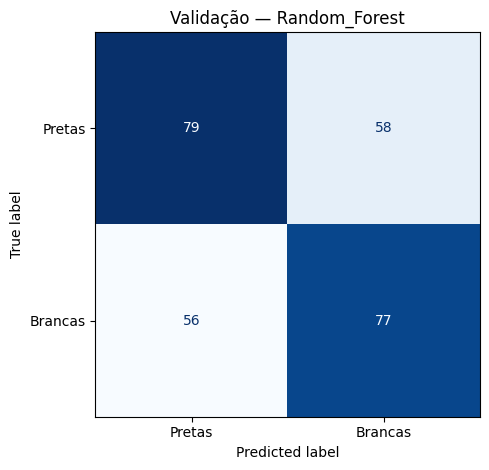

In [2]:
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

PRONTO = (PASTA / 'selecao_congelada.json').exists()
modelo = None
if PRONTO:
    modelo, selecao = carregar_selecionado()
    val = carregar_dados('val')
    X_val, y_val = separar_xy(val)
    metricas, predicoes = avaliar_modelo(modelo, val)
    display(pd.Series(metricas, name='val').to_frame())
    ConfusionMatrixDisplay.from_predictions(predicoes.y_real, predicoes.y_pred,
        labels=[0, 1], display_labels=['Pretas', 'Brancas'], cmap='Blues', colorbar=False)
    plt.title(f"Validação — {selecao['modelo']}")
    plt.tight_layout(); plt.savefig(FIGURAS / '05_confusao_val.png', dpi=180); plt.show()
else:
    print('Execute primeiro a seleção no notebook 04.')


## 2. Importância por permutação no conjunto de validação

Embaralhamos um atributo por vez, mantendo o pipeline fixo, e medimos a redução da ROC-AUC. Uma importância positiva sugere que o pipeline usa informação desse atributo. Importâncias negativas podem refletir ruído ou variação da amostra.

Preditores correlacionados podem substituir uns aos outros e dividir sua importância. Atributos descartados pelo seletor tendem a ter importância zero. O desvio padrão abaixo descreve repetições da permutação, não um intervalo de confiança populacional.


,atributo,queda_auc_media,dp_repeticoes,selecionado
2,komi,0.070600,0.019851,True
1,rank_w,0.029255,0.015063,True
13,distancia_media_tengen_w,0.013682,0.007747,True
12,distancia_media_tengen_b,0.009720,0.007055,True
17,tamanho_medio_grupos_w,0.007332,0.003644,True
7,liberdades_maior_grupo_w,0.005335,0.006413,True
19,liberdades_medias_grupos_w,0.005332,0.005074,True
15,quantidade_grupos_w,0.004684,0.002497,True
14,quantidade_grupos_b,0.002947,0.003543,True
6,liberdades_maior_grupo_b,0.002099,0.005574,True


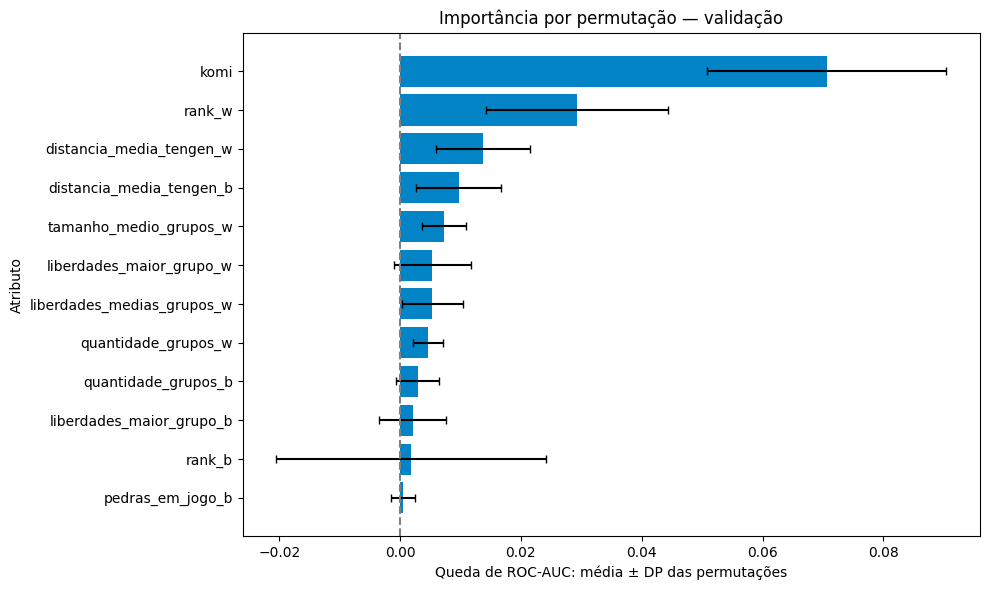

In [3]:
EXECUTAR_IMPORTANCIA = True
REPETICOES_PERMUTACAO = 20
importancias = pd.DataFrame()
if PRONTO and EXECUTAR_IMPORTANCIA:
    resultado = permutation_importance(modelo, X_val, y_val, scoring='roc_auc',
        n_repeats=REPETICOES_PERMUTACAO, random_state=SEED,
        n_jobs=1)
    importancias = pd.DataFrame({'atributo': ATRIBUTOS,
        'queda_auc_media': resultado.importances_mean,
        'dp_repeticoes': resultado.importances_std,
        'selecionado': modelo.named_steps['select'].get_support()})
    importancias = importancias.sort_values('queda_auc_media', ascending=False)
    display(importancias)
    importancias.to_csv(PASTA / 'importancia_permutacao_val.csv', index=False)
    top = importancias.head(12).sort_values('queda_auc_media')
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top.atributo, top.queda_auc_media, xerr=top.dp_repeticoes,
        capsize=3, color='#0284c7')
    ax.axvline(0, color='gray', linestyle='--')
    ax.set(xlabel='Queda de ROC-AUC: média ± DP das permutações', ylabel='Atributo',
        title='Importância por permutação — validação')
    fig.tight_layout(); fig.savefig(FIGURAS / '05_permutation_importance.png', dpi=180); plt.show()


## 3. Dependência parcial opcional

O gráfico calcula a resposta média prevista ao variar um atributo. Para preditores correlacionados, pode avaliar combinações pouco plausíveis. A resposta de SVM é margem de decisão; nos demais pipelines é probabilidade prevista, cuja calibração não foi demonstrada.


c:\venv\ilumpy\Lib\site-packages\sklearn\inspection\_partial_dependence.py:717: FutureWarning: The column 1 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(


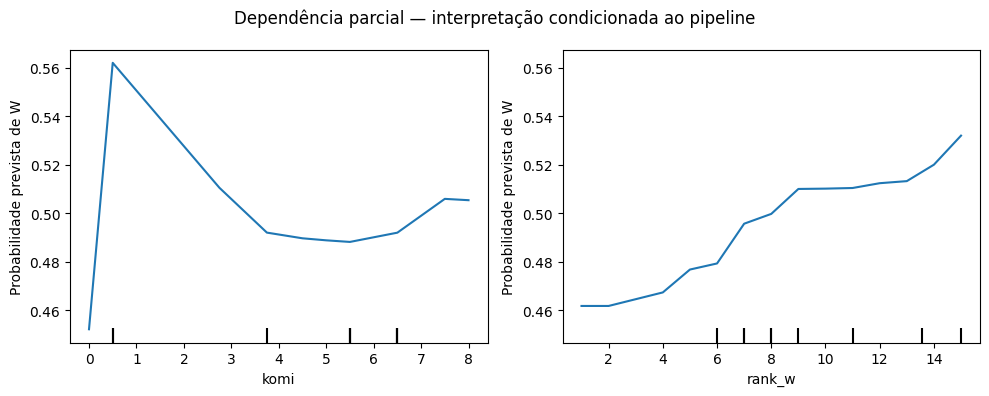

In [4]:
EXECUTAR_DEPENDENCIA_PARCIAL = True
if PRONTO and EXECUTAR_DEPENDENCIA_PARCIAL and len(importancias):
    escolhidos = importancias.loc[importancias.selecionado, 'atributo'].head(2).tolist()
    if escolhidos:
        fig, axes = plt.subplots(1, len(escolhidos), figsize=(10, 4), squeeze=False)
        PartialDependenceDisplay.from_estimator(modelo, X_val, features=escolhidos,
            grid_resolution=20, response_method='auto', ax=axes.flat[:len(escolhidos)])
        _, tipo = pontuacoes(modelo, X_val)
        for ax in axes.flat:
            ax.set_ylabel('Probabilidade prevista de W' if tipo == 'probabilidade_W' else 'Margem de decisão para W')
        fig.suptitle('Dependência parcial — interpretação condicionada ao pipeline')
        fig.tight_layout(); fig.savefig(FIGURAS / '05_dependencia_parcial.png', dpi=180); plt.show()
else:
    print('Dependência parcial opcional desativada ou ainda sem importâncias calculadas.')


## 4. Diagnóstico descritivo por subgrupos

Compare partidas com e sem handicap e faixas da diferença de ranks. Pequenos grupos e grupos com apenas uma classe exigem cautela; ROC-AUC fica indefinida quando só há uma classe. Não há testes de hipótese ou comprovação de diferença populacional nesta tabela.


In [5]:
if PRONTO:
    detalhe = val[['game_id', 'handicap', 'rank_b', 'rank_w']].merge(
        predicoes, on='game_id', validate='one_to_one')
    detalhe['grupo_handicap'] = np.select([detalhe.handicap.isna(), detalhe.handicap.gt(0)],
        ['ausente', 'com handicap'], default='sem handicap')
    diferenca = detalhe.rank_w - detalhe.rank_b
    detalhe['grupo_rank'] = np.select([diferenca.lt(-2), diferenca.gt(2)],
        ['W pelo menos 3 unidades abaixo', 'W pelo menos 3 unidades acima'],
        default='Diferença entre -2 e +2')
    linhas = []
    for variavel in ['grupo_handicap', 'grupo_rank']:
        for grupo, sub in detalhe.groupby(variavel):
            m = metricas_predicoes(sub.y_real, sub.y_pred, sub.score_W)
            linhas.append({'recorte': variavel, 'grupo': grupo, **m,
                'n_B': int(sub.y_real.eq(0).sum()), 'n_W': int(sub.y_real.eq(1).sum()),
                'grupo_pequeno': len(sub) < 30})
    subgrupos = pd.DataFrame(linhas)
    display(subgrupos)
    subgrupos.to_csv(PASTA / 'diagnostico_subgrupos_val.csv', index=False)
    detalhe.to_csv(PASTA / 'diagnostico_partidas_val.csv', index=False)
    print('Exemplos de erros; score é probabilidade ou margem conforme tipo_score:')
    display(detalhe.loc[~detalhe.acertou].head(10))


,recorte,grupo,n,accuracy,balanced_accuracy,f1_macro,roc_auc,n_B,n_W,grupo_pequeno
0,grupo_handicap,com handicap,29,0.620690,0.500000,0.382979,0.494949,11,18,True
1,grupo_handicap,sem handicap,241,0.572614,0.570014,0.569650,0.599517,126,115,False
2,grupo_rank,Diferença entre -2 e +2,218,0.559633,0.559633,0.559299,0.601549,109,109,False
3,grupo_rank,W pelo menos 3 unidades abaixo,17,0.647059,0.458333,0.392857,0.516667,12,5,True
4,grupo_rank,W pelo menos 3 unidades acima,35,0.657143,0.625000,0.580000,0.555921,16,19,False


Exemplos de erros; score é probabilidade ou margem conforme tipo_score:


,game_id,handicap,rank_b,rank_w,y_real,y_pred,score_W,tipo_score,acertou,grupo_handicap,grupo_rank
0,val:0000/00000080,4.0,1,7,0,1,0.628459,probabilidade_W,False,com handicap,W pelo menos 3 unidades acima
1,val:0000/00000170,0.0,15,15,1,0,0.481054,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
2,val:0000/00000241,0.0,9,9,0,1,0.506941,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
4,val:0000/00000325,0.0,7,8,0,1,0.594622,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
7,val:0000/00000448,0.0,6,7,0,1,0.607563,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
10,val:0000/00000575,0.0,7,7,0,1,0.500558,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
13,val:0000/00000655,0.0,11,11,0,1,0.500516,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
14,val:0000/00000682,0.0,7,8,1,0,0.493998,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
18,val:0000/00000822,0.0,9,8,0,1,0.500676,probabilidade_W,False,sem handicap,Diferença entre -2 e +2
22,val:0001/00001069,0.0,13,13,1,0,0.413542,probabilidade_W,False,sem handicap,Diferença entre -2 e +2


## Análise

Na validação, o modelo apresentou 156 acertos e 114 erros.  
Komi e rank_w tiveram quedas de AUC por permutação de 0,0706 e 0,0293.  
A dependência parcial foi crescente para rank_w e não monotônica para komi.  
O subgrupo com handicap apresentou AUC de 0,4949, com apenas 29 partidas.

## Conclusões e principais aprendizados

O Random Forest manteve ROC-AUC de 0,6083 na validação.  
As condições iniciais se destacaram na importância preditiva deste modelo.  
Correlações e grupos pequenos limitam a interpretação, sem demonstrar causalidade.  
O pipeline foi preservado para a avaliação final.

## Descrição do uso de IA neste trabalho

O ChatGPT auxiliou na implementação e organização das análises.  
Também apoiou a interpretação das importâncias, dos gráficos e dos subgrupos.

## Referências consultadas

- Cassar, D. R. *Criaturas Lendárias do Reino de Lumi e onde encontrá-las*, seção 4, Tiamat, pp. 7–9. Material da ATP-203 fornecido no projeto.
- [scikit-learn: prevenção de vazamento e pipelines](https://scikit-learn.org/stable/common_pitfalls.html).
- [scikit-learn: validação cruzada](https://scikit-learn.org/stable/modules/cross_validation.html).
- [scikit-learn: métricas de classificação](https://scikit-learn.org/stable/modules/model_evaluation.html).
- [Optuna: estudos persistentes](https://optuna.readthedocs.io/en/stable/tutorial/20_recipes/001_rdb.html).
- [Optuna: Study e estados dos trials](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html).
- [scikit-learn: permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).
- [scikit-learn: dependência parcial](https://scikit-learn.org/stable/modules/partial_dependence.html).
- [scikit-learn: SelectKBest](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectKBest.html).
- [XGBoost: hiperparâmetros](https://xgboost.readthedocs.io/en/stable/parameter.html).

Consulta: 11/11/2026. Complete a referência da fonte original dos SGFs com o endereço e a data de obtenção realmente utilizados.
